# Install necessary functions


In [6]:
import os
import numpy as np
import pandas as pd
import nibabel as nib
from nilearn.image import load_img, resample_to_img, index_img
from nilearn.masking import intersect_masks, apply_mask, unmask
from nilearn.signal import clean
from nilearn.interfaces.fmriprep import load_confounds
import glob
import re
import matplotlib.pyplot as plt


## Set User Parameters

In [7]:
# -----------------------------------------------------------------------------
# 1) USER PARAMETERS
# -----------------------------------------------------------------------------

# Where your fmriprep lives
base_dir    = r"C:\Users\William\Narratives\fmriprep"
task_label  = 'black'
output_mask = os.path.join(base_dir,
                           f'group_task-{task_label}_intersect_mask.nii.gz')

# TR indices to keep
tr_slice = slice(11, 171)   # Adjust based on stim timing
TR = 1.5

# Exclusions
exclude_subs     = []
exclude_sub_runs = ""

# Which BOLD space / resolution to use
preferred_space = 'MNI152NLin2009cAsym'
preferred_res   = 'native'

# *** New: set this if you only want to process one subject ***
# e.g. target_subject = 'sub-002' 
# or target_subject = None  to run on all (minus excluded)
target_subject = None


intersect = load_img(os.path.join(base_dir, 'derivatives',f'{task_label}_masks',f'group_task-{task_label}_intersect_mask.nii.gz'))




## Set subjects list

In [8]:
# -----------------------------------------------------------------------------
# 2) BUILD LIST OF SUBJECTS
# -----------------------------------------------------------------------------
all_subs = sorted(d for d in os.listdir(base_dir)
                  if d.startswith('sub-')
                  and os.path.isdir(os.path.join(base_dir, d)))
if target_subject:
    if target_subject not in all_subs:
        raise ValueError(f"{target_subject} not found under {base_dir}")
    subjects = [target_subject]
else:
    subjects = [s for s in all_subs if s not in exclude_subs]

In [9]:
import nilearn
print(nilearn.__version__)

import inspect
from nilearn.signal import clean
print(inspect.signature(clean))

0.12.0
(signals, runs=None, detrend=True, standardize='zscore', sample_mask=None, confounds=None, standardize_confounds=True, filter='butterworth', low_pass=None, high_pass=None, t_r=2.5, ensure_finite=False, extrapolate=True, **kwargs)


## Process Bold Run/Clean the timeseries signal

In [10]:
# -----------------------------------------------------------------------------
# 4) PROCESS EACH VALID BOLD RUN (native‑res, already aligned)
# -----------------------------------------------------------------------------
space_res = f"space-{preferred_space}_res-{preferred_res}"

cleaned_count = 0

for sub in subjects:
    func_dir = os.path.join(base_dir, sub, "func")
    # collect preproc BOLD files
    run_pat    = os.path.join(func_dir,
                   f"{sub}_task-{task_label}_run-*_{space_res}_desc-preproc_bold.nii.gz")
    single_pat = os.path.join(func_dir,
                   f"{sub}_task-{task_label}_{space_res}_desc-preproc_bold.nii.gz")
    bold_files = sorted(glob.glob(run_pat)) + sorted(glob.glob(single_pat))
    if not bold_files:
        print(f"Skipping {sub}: no preproc BOLD")
        continue

    for bf in bold_files:
        run_m = re.search(r"_run-(\d+)_", os.path.basename(bf))
        run   = run_m.group(1) if run_m else None
        if run and (sub,run) in exclude_sub_runs:
            print(f"  • skipping {sub} run-{run}")
            continue

        # flexible confounds lookup
        if run:
            conf_pat = os.path.join(func_dir,
                f"{sub}_task-{task_label}_run-{run}_desc-confounds*.tsv")
        else:
            conf_pat = os.path.join(func_dir,
                f"{sub}_task-{task_label}_desc-confounds*.tsv")

        confs = sorted(glob.glob(conf_pat))

        # Assert we have confounds for each file
        assert confs, f"[{os.path.basename(bf)}] Missing confounds (checked {conf_pat})"


        conf_file = confs[0]

        print(f"\nProcessing {sub}{'_run-'+run if run else ''}: {os.path.basename(bf)}")
        bold_img = load_img(bf)

        # ── SANITY CHECK alignment ─────────────────────────────────────────────
        # Make sure shapes and affines exactly match the intersect mask; otherwise skip.
        assert bold_img.shape[:3] == intersect.shape, \
               f"[{sub}{run}] shape mismatch: bold {bold_img.shape[:3]} vs mask {intersect.shape}"
        assert np.allclose(bold_img.affine, intersect.affine), \
               f"[{sub}{run}] affine mismatch between bold and mask"

        # ─────────────────────────────────────────────────────────────────────────



        # -----------------------------------------------------------------------------
        # LOAD CONFOUNDS via nilearn’s fmriprep interface
        # -----------------------------------------------------------------------------
        print("Loading confounds…")
        confounds_df, sample_mask = load_confounds(
        img_files    = bf,
        strategy     = ('motion', 'high_pass', 'wm_csf'),
        motion       = 'full',
        wm_csf       = 'basic',
        global_signal= 'basic',
        compcor      = 'anat_combined',
        n_compcor    = 'all',
        ica_aroma    = 'full',
        scrub        = 5,
        fd_threshold = 0.2,
        std_dvars_threshold = 3,
        demean       = True
        )

        
        #   clean up infinities / NaNs
        # confounds_df.replace([np.inf, -np.inf], np.nan, inplace=True)
        # confounds_df.fillna(0, inplace=True)


        # extract TR and mask‐then‐clean
        tr = float(bold_img.header.get_zooms()[3])
        ts = apply_mask(bold_img, intersect)
        assert tr in (1500,1.5), f"TR mismatch: {tr} vs 1500"
        print("shape of time series:", ts.shape)
        # assert ts.shape == (300,43981), f'unexpected shape {ts.shape} should be (300,43981)' 


        # full‐length clean with every kwarg spelled out
        ts_clean = clean(
        signals         = ts,
        runs            = None,
        detrend         = True,
        standardize     = 'zscore_sample',    # use sample‐std zscore
        sample_mask     = None,
        confounds       = confounds_df,
        standardize_confounds = True,
        low_pass        = 0.1,
        high_pass       = 0.01,
        t_r             = TR,
        ensure_finite   = True,
        )

        # back to 4D NIfTI
        cleaned_img = unmask(ts_clean, intersect)

        # now select only our TR window via index_img
        sel_img = index_img(cleaned_img, tr_slice)

        # --- ADD THIS LINE to fix TR in the header ---
        sel_img.header.set_zooms(sel_img.header.get_zooms()[:3] + (TR,))

        # sanity check: should be 160 TRs
        # assert sel_img.shape == (65,77,49,160), f'unexpected shape {sel_img.shape} should be (65,77,49,160)' 


        # save into derivatives/pieMan_cleaned
        run_tag   = f"_run-{run}" if run else ""
        deriv_dir = os.path.join(base_dir, "derivatives", f"{task_label}_cleaned")
        out_dir   = os.path.join(deriv_dir, sub, "func")
        os.makedirs(out_dir, exist_ok=True)

        out_file = os.path.join(out_dir,
                     f"{sub}_task-{task_label}{run_tag}_cleaned_desc-masked_bold.nii.gz")
        sel_img.to_filename(out_file)
        print("  → saved to:", out_file)
        
        
        cleaned_count += 1

print("\nALL DONE.")


assert cleaned_count == 75, f"❌ Expected to clean 75 files, but cleaned {cleaned_count}."    # Add dict for number of subs for other stims
print(f"✅ Successfully cleaned {cleaned_count} files.")

Skipping sub-001: no preproc BOLD
Skipping sub-002: no preproc BOLD
Skipping sub-003: no preproc BOLD
Skipping sub-004: no preproc BOLD
Skipping sub-005: no preproc BOLD
Skipping sub-006: no preproc BOLD
Skipping sub-007: no preproc BOLD
Skipping sub-008: no preproc BOLD
Skipping sub-009: no preproc BOLD
Skipping sub-010: no preproc BOLD
Skipping sub-011: no preproc BOLD
Skipping sub-012: no preproc BOLD
Skipping sub-013: no preproc BOLD
Skipping sub-014: no preproc BOLD
Skipping sub-015: no preproc BOLD
Skipping sub-016: no preproc BOLD
Skipping sub-017: no preproc BOLD
Skipping sub-018: no preproc BOLD
Skipping sub-019: no preproc BOLD
Skipping sub-020: no preproc BOLD
Skipping sub-021: no preproc BOLD
Skipping sub-022: no preproc BOLD
Skipping sub-023: no preproc BOLD
Skipping sub-024: no preproc BOLD
Skipping sub-025: no preproc BOLD
Skipping sub-026: no preproc BOLD
Skipping sub-027: no preproc BOLD
Skipping sub-028: no preproc BOLD
Skipping sub-029: no preproc BOLD
Skipping sub-0

C:\Users\William\AppData\Local\Temp\ipykernel_182752\2611369961.py:91: DeprecationWarning: The default strategy for standardize is currently 'zscore' which incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.13, the default strategy will be replaced by the new strategy and the 'zscore' option will be removed. Please use 'zscore_sample' instead.
  ts_clean = clean(


  → saved to: C:\Users\William\Narratives\fmriprep\derivatives\black_cleaned\sub-127\func\sub-127_task-black_cleaned_desc-masked_bold.nii.gz
Skipping sub-128: no preproc BOLD
Skipping sub-129: no preproc BOLD
Skipping sub-130: no preproc BOLD
Skipping sub-131: no preproc BOLD
Skipping sub-132: no preproc BOLD
Skipping sub-133: no preproc BOLD
Skipping sub-134: no preproc BOLD
Skipping sub-135: no preproc BOLD
Skipping sub-136: no preproc BOLD
Skipping sub-137: no preproc BOLD
Skipping sub-138: no preproc BOLD
Skipping sub-139: no preproc BOLD
Skipping sub-140: no preproc BOLD
Skipping sub-141: no preproc BOLD
Skipping sub-142: no preproc BOLD
Skipping sub-143: no preproc BOLD
Skipping sub-144: no preproc BOLD
Skipping sub-145: no preproc BOLD
Skipping sub-146: no preproc BOLD
Skipping sub-147: no preproc BOLD
Skipping sub-148: no preproc BOLD
Skipping sub-149: no preproc BOLD
Skipping sub-150: no preproc BOLD
Skipping sub-151: no preproc BOLD
Skipping sub-152: no preproc BOLD
Skipping 

C:\Users\William\AppData\Local\Temp\ipykernel_182752\2611369961.py:91: DeprecationWarning: The default strategy for standardize is currently 'zscore' which incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.13, the default strategy will be replaced by the new strategy and the 'zscore' option will be removed. Please use 'zscore_sample' instead.
  ts_clean = clean(


  → saved to: C:\Users\William\Narratives\fmriprep\derivatives\black_cleaned\sub-265\func\sub-265_task-black_cleaned_desc-masked_bold.nii.gz
Skipping sub-266: no preproc BOLD

Processing sub-267: sub-267_task-black_space-MNI152NLin2009cAsym_res-native_desc-preproc_bold.nii.gz
Loading confounds…
shape of time series: (550, 111509)


C:\Users\William\AppData\Local\Temp\ipykernel_182752\2611369961.py:91: DeprecationWarning: The default strategy for standardize is currently 'zscore' which incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.13, the default strategy will be replaced by the new strategy and the 'zscore' option will be removed. Please use 'zscore_sample' instead.
  ts_clean = clean(


... (84 outputs left out)

  → saved to: C:\Users\William\Narratives\fmriprep\derivatives\black_cleaned\sub-314\func\sub-314_task-black_cleaned_desc-masked_bold.nii.gz

Processing sub-315: sub-315_task-black_space-MNI152NLin2009cAsym_res-native_desc-preproc_bold.nii.gz
Loading confounds…
shape of time series: (550, 111509)


C:\Users\William\AppData\Local\Temp\ipykernel_182752\2611369961.py:91: DeprecationWarning: The default strategy for standardize is currently 'zscore' which incorrectly uses population std to calculate sample zscores. The new strategy 'zscore_sample' corrects this behavior by using the sample std. In release 0.13, the default strategy will be replaced by the new strategy and the 'zscore' option will be removed. Please use 'zscore_sample' instead.
  ts_clean = clean(


  → saved to: C:\Users\William\Narratives\fmriprep\derivatives\black_cleaned\sub-315\func\sub-315_task-black_cleaned_desc-masked_bold.nii.gz
Skipping sub-316: no preproc BOLD
Skipping sub-317: no preproc BOLD
Skipping sub-318: no preproc BOLD
Skipping sub-319: no preproc BOLD
Skipping sub-320: no preproc BOLD
Skipping sub-321: no preproc BOLD
Skipping sub-322: no preproc BOLD
Skipping sub-323: no preproc BOLD
Skipping sub-324: no preproc BOLD
Skipping sub-325: no preproc BOLD
Skipping sub-326: no preproc BOLD
Skipping sub-327: no preproc BOLD
Skipping sub-328: no preproc BOLD
Skipping sub-329: no preproc BOLD
Skipping sub-330: no preproc BOLD
Skipping sub-331: no preproc BOLD
Skipping sub-332: no preproc BOLD
Skipping sub-333: no preproc BOLD
Skipping sub-334: no preproc BOLD
Skipping sub-335: no preproc BOLD
Skipping sub-336: no preproc BOLD
Skipping sub-337: no preproc BOLD
Skipping sub-338: no preproc BOLD
Skipping sub-339: no preproc BOLD
Skipping sub-340: no preproc BOLD
Skipping 

AssertionError: ❌ Expected to clean 75 files, but cleaned 46.

## Optional Visualize and Voxel Count for sanity check 

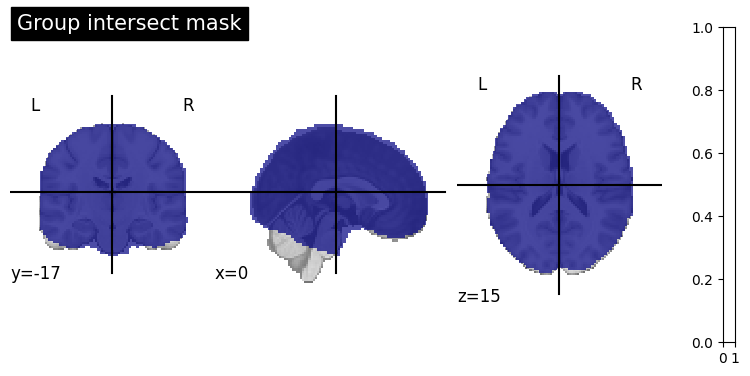

In [11]:
from nilearn.plotting import plot_roi
plot_roi(intersect, title='Group intersect mask')

In [12]:
import numpy as np
import nibabel as nib
grp = intersect.get_fdata().astype(bool)
print("Group mask voxels:", grp.sum())

Group mask voxels: 111509


## Pre-clean vs. Post-clean voxel timeseries

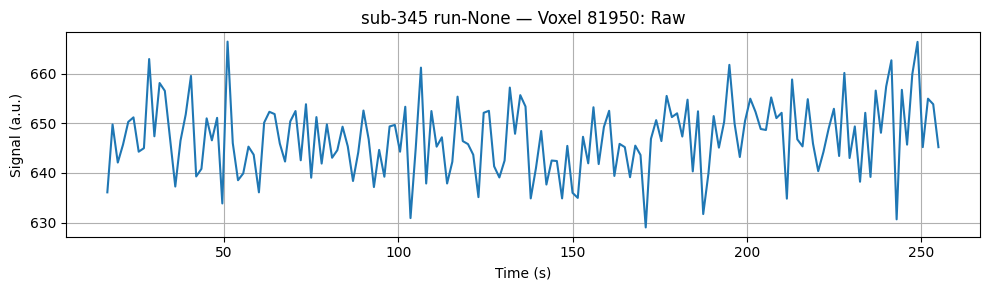

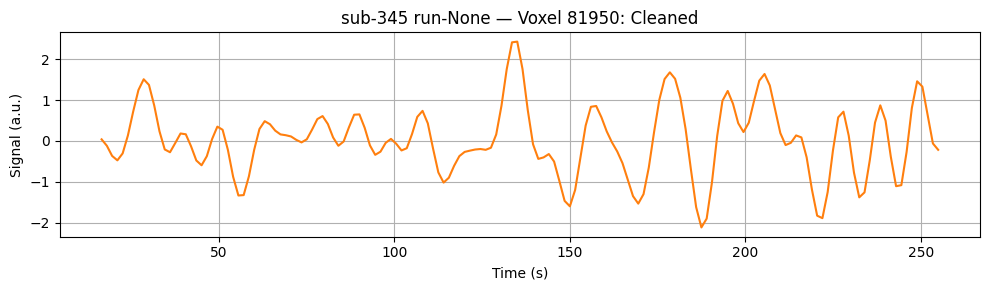

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1) extract just the window you processed
X_raw = ts[tr_slice, :]       # (n_TRs_sub, n_voxels)
X_cln = ts_clean[tr_slice, :] # same shape

n_TRs_sub, n_vox = X_raw.shape

# 2) build a time axis in seconds
time_axis = np.arange(n_TRs_sub) * TR + (tr_slice.start * TR)

# 3) choose a single voxel (random or fixed)
v_idx = np.random.randint(n_vox)   # or set v_idx = 42

# 4) Plot raw on its own figure
plt.figure(figsize=(10, 3))
plt.plot(time_axis, X_raw[:, v_idx], color='tab:blue')
plt.title(f"{sub} run-{run} — Voxel {v_idx}: Raw")
plt.xlabel("Time (s)")
plt.ylabel("Signal (a.u.)")
plt.grid(True)
plt.tight_layout()

# 5) Plot cleaned on its own figure
plt.figure(figsize=(10, 3))
plt.plot(time_axis, X_cln[:, v_idx], color='tab:orange')
plt.title(f"{sub} run-{run} — Voxel {v_idx}: Cleaned")
plt.xlabel("Time (s)")
plt.ylabel("Signal (a.u.)")
plt.grid(True)
plt.tight_layout()

plt.show()